# BDG2: FedAvg contra treino centralizado e treino só local

Cada site do BDG2 é um cliente da federação. A tarefa é prever o consumo de eletricidade da próxima
hora de cada edificação. O treino usa 2016 e a validação usa 2017. A seleção dos sites e das
edificações e as diferenças entre os clientes estão em `eda.ipynb`.

Configuração:

- **Features (17):** lags da eletricidade em t-1, t-24 e t-168; hora do dia e dia da semana
  (seno e cosseno); temperatura do ar e ponto de orvalho; lag t-1 dos medidores opcionais (água
  gelada, vapor, água quente e gás), com uma flag de presença para cada um. Quando a edificação não
  tem o medidor, a feature vale 0 e a flag também.
- **Normalização:** z-score por edificação, com estatísticas de 2016.
- **Modelo:** MLP 17 → 64 → 64 → 1, Adam, taxa de aprendizado 1e-3.
- **FedAvg:** 30 rodadas, todos os clientes em toda rodada, 2 épocas locais, média ponderada pelo
  número de amostras.
- **Comparações:** o mesmo modelo treinado com todos os dados juntos (centralizado), um modelo por
  site treinado só com os dados dele (só local) e um random walk, que prevê que a próxima hora
  repete a hora atual: ŷ(t) = y(t−1). O random walk é a referência mínima: um modelo que não ganha
  dele não acrescenta nada a olhar a última leitura.
  Centralizado e só local treinam 60 épocas, o mesmo número de passadas pelos dados que o FedAvg
  faz.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from bdg2_fl import baselines, fedavg
from bdg2_fl import graficos as gr
from bdg2_fl.config import MEDIDORES_OPCIONAIS
from bdg2_fl.dados import FEATURES, construir, tensores
from bdg2_fl.metricas import rmse_cv
from bdg2_fl.modelo import prever

gr.aplicar_estilo()
pd.set_option("display.precision", 2)

clientes = construir()
sites = list(clientes)
cores = gr.cores_sites(sites)
dados = {}
for s, c in clientes.items():
    Xtr, ytr = tensores(c["treino"])
    Xva, yva = tensores(c["val"])
    dados[s] = {"Xtr": Xtr, "ytr": ytr, "Xva": Xva, "yva": yva}

NOMES = {"chilledwater": "água gelada", "steam": "vapor", "hotwater": "água quente", "gas": "gás"}
pd.DataFrame({
    s: {"edificações": len(c["edificacoes"]),
        "linhas de treino": len(c["treino"]),
        "linhas de validação": len(c["val"])}
    | {f"com {NOMES[m]}": int(c["treino"].groupby("edif")[f"tem_{m}"].first().sum())
       for m in MEDIDORES_OPCIONAIS}
    for s, c in clientes.items()
}).T

,edificações,linhas de treino,linhas de validação,com água gelada,com vapor,com água quente,com gás
Rat,20,172156,174056,0,0,0,0
Hog,20,172320,175200,7,11,0,0
Fox,20,172208,175128,16,0,11,0
Bull,20,161680,170578,11,11,0,0
Eagle,20,168898,172678,16,9,10,0
Bear,20,172214,175061,0,0,0,0


## 1. FedAvg

Em cada rodada (implementação em `src/bdg2_fl/fedavg.py`):

1. o servidor envia os pesos globais w para todos os clientes;
2. cada cliente k treina 2 épocas nos próprios dados, partindo de w, e chega a w_k;
3. o cliente devolve a atualização Δw_k = w_k − w;
4. o servidor faz a média ponderada w ← Σ (n_k / n) · w_k.

O que volta para o servidor é uma atualização de pesos acumulada ao longo de várias épocas locais,
não um gradiente.

In [2]:
t0 = time.time()
m_fed, hist = fedavg.rodar(dados, len(FEATURES), log=lambda *_: None)
print(f"FedAvg: {time.time() - t0:.0f} s")

pd.DataFrame([
    {"rodada": h["rodada"], "perda val global (MSE em z)": h["perda_val_global"],
     "‖Δw‖ médio": np.mean([c["norma_delta"] for c in h["clientes"].values()]) if h["clientes"] else np.nan}
    for h in hist if h["rodada"] in (0, 1, 2, 3, 5, 10, 20, 30)
]).set_index("rodada")

FedAvg: 33 s


,perda val global (MSE em z),‖Δw‖ médio
rodada,,
0,1.13,NaN
1,0.12,3.21
2,0.11,2.59
3,0.11,2.12
5,0.11,1.75
10,0.11,1.60
20,0.11,1.53
30,0.11,1.48


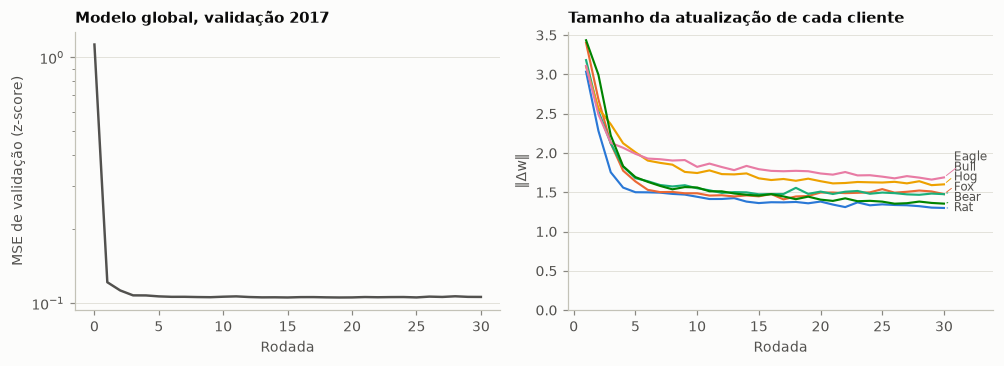

In [3]:
rodadas = [h["rodada"] for h in hist[1:]]
fig, (a, b) = plt.subplots(1, 2, figsize=(9.2, 3.4))

a.plot([h["rodada"] for h in hist], [h["perda_val_global"] for h in hist], color=gr.TINTA_2)
a.set_yscale("log")
a.set_xlabel("Rodada")
a.set_ylabel("MSE de validação (z-score)")
a.set_title("Modelo global, validação 2017")

finais = {}
for s in sites:
    v = [h["clientes"][s]["norma_delta"] for h in hist[1:]]
    b.plot(rodadas, v, color=cores[s], linewidth=1.4)
    finais[s] = v[-1]
# rótulos no fim das linhas, afastados entre si para não se sobreporem
pos, ant = {}, -np.inf
for s, v in sorted(finais.items(), key=lambda t: t[1]):
    pos[s] = ant = max(v, ant + 0.13)
for s in sites:
    b.annotate(s, (rodadas[-1], finais[s]), xytext=(rodadas[-1] + 0.8, pos[s]),
               textcoords="data", va="center", fontsize=8, color=gr.TINTA_2,
               arrowprops={"arrowstyle": "-", "color": cores[s], "linewidth": 0.6})
b.set_xlabel("Rodada")
b.set_ylabel("‖Δw‖")
b.set_title("Tamanho da atualização de cada cliente")
b.set_xlim(right=rodadas[-1] + 4)
b.set_ylim(bottom=0)
fig.tight_layout()
plt.show()

A perda de validação do modelo global cai de 1,13 para 0,12 já na primeira rodada e fica em
~0,11 a partir da terceira. As outras 27 rodadas quase não mudam o modelo global.

O tamanho das atualizações dos clientes, por outro lado, não vai a zero. Ele cai de ~3,2 para
~1,5 e estabiliza ali. A cada rodada, cada cliente continua puxando o modelo para o próprio ótimo,
e a média desfaz esses puxões. Esse é o efeito conhecido como *client drift*, típico de dados
não-IID. Eagle e Bull são os clientes que mais puxam.

## 2. Comparação com centralizado, só local e random walk

In [4]:
t0 = time.time()
m_cen = baselines.centralizado(dados, len(FEATURES))
print(f"centralizado: {time.time() - t0:.0f} s")
t0 = time.time()
m_loc = baselines.locais(dados, len(FEATURES))
print(f"só local: {time.time() - t0:.0f} s")


def kwh(modelo, s):
    va = clientes[s]["val"]
    return prever(modelo, dados[s]["Xva"]).squeeze(1).numpy() * va["sd"].values + va["mu"].values


prev = {s: {"federado": kwh(m_fed, s), "centralizado": kwh(m_cen, s), "local": kwh(m_loc[s], s),
            "random_walk": clientes[s]["val"]["rw_kwh"].values} for s in sites}
real = {s: clientes[s]["val"]["y_kwh"].values for s in sites}
metodos = list(gr.METODOS)

linhas = {s: {m: rmse_cv(real[s], prev[s][m]) for m in metodos} for s in sites}
linhas["Total"] = {m: rmse_cv(np.concatenate([real[s] for s in sites]),
                              np.concatenate([prev[s][m] for s in sites])) for m in metodos}

cv = pd.DataFrame({k: {gr.METODOS[m][0]: 100 * v[m]["cv_rmse"] for m in metodos} for k, v in linhas.items()}).T
rmse = pd.DataFrame({k: {gr.METODOS[m][0]: v[m]["rmse"] for m in metodos} for k, v in linhas.items()}).T
pd.concat({"CV(RMSE) %": cv, "RMSE (kWh)": rmse}, axis=1)

centralizado: 29 s


só local: 54 s


CV(RMSE) %                                   RMSE (kWh)               \
          FedAvg Centralizado Só local Random walk     FedAvg Centralizado   
Rat        16.36        21.23    12.22       16.84      52.59        68.23   
Hog        15.74        16.55    15.46       16.56      26.99        28.40   
Fox         7.22         6.98     6.79        8.82      20.38        19.70   
Bull       17.72        16.81    16.63       18.54      18.13        17.20   
Eagle       7.39         7.31     7.26        8.65      19.02        18.81   
Bear        9.09         8.48     8.23       13.75      12.30        11.48   
Total      13.28        15.69    11.20       14.37      28.16        33.27   

                            
      Só local Random walk  
Rat      39.27       54.13  
Hog      26.52       28.41  
Fox      19.18       24.90  
Bull     17.02       18.97  
Eagle    18.69       22.26  
Bear     11.13       18.60  
Total    23.74       30.46

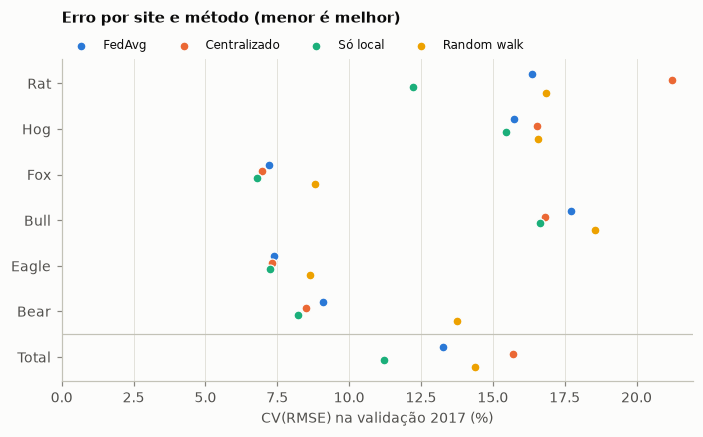

In [5]:
ordem = sites + ["Total"]
fig, ax = plt.subplots(figsize=(7.4, 3.8))
desloc = {"federado": -0.21, "centralizado": -0.07, "local": 0.07, "random_walk": 0.21}
for m in metodos:
    nome, cor = gr.METODOS[m]
    y = [i + desloc[m] for i in range(len(ordem))]
    ax.scatter(cv.loc[ordem, nome], y, color=cor, s=34, label=nome, zorder=3,
               edgecolor=gr.SUPERFICIE, linewidth=0.8)
ax.set_yticks(range(len(ordem)), ordem)
ax.invert_yaxis()
ax.axhline(len(sites) - 0.5, color=gr.EIXO, linewidth=0.8)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("CV(RMSE) na validação 2017 (%)")
ax.set_xlim(left=0)
ax.set_title("Erro por site e método (menor é melhor)", pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncols=4, borderaxespad=0.2)
plt.show()

O random walk erra 14,4% no total. Ele é a referência mínima: prever que a próxima hora repete a
atual. O FedAvg ganha dele em todos os sites, mas por pouco: 13,3% no total, e em Rat, Hog e Bull a
vantagem fica abaixo de 1 ponto (0,5, 0,8 e 0,8). O modelo global acrescenta pouco a olhar a última
leitura.

O treino só local é o melhor em todos os seis sites e o único que se afasta do random walk de forma
consistente: 11,2% no total, 3,2 pontos abaixo dele. Fora de Rat, a vantagem do local sobre o FedAvg
é pequena, de 0,1 a 1,1 ponto. Em Rat, é de 4,1 pontos (16,4% contra 12,2%), o que basta para deixar
o FedAvg 2,1 pontos atrás no total.

O centralizado, que treina com os dados de todos os sites juntos, não resolve. Ele fica perto do
FedAvg na maioria dos sites, mas é o pior dos três em Rat (21,2%), em Hog e no total (15,7%). Em Rat
e no total, fica pior até que o random walk.

## 3. Os clientes são não-IID?

Um teste direto: aplicar o modelo treinado só com os dados de um site nos outros sites. Cada
célula é o erro desse modelo dividido pelo erro do modelo local do próprio site avaliado. A
diagonal vale 1 por construção. Se os clientes fossem parecidos, as outras células também ficariam
perto de 1.

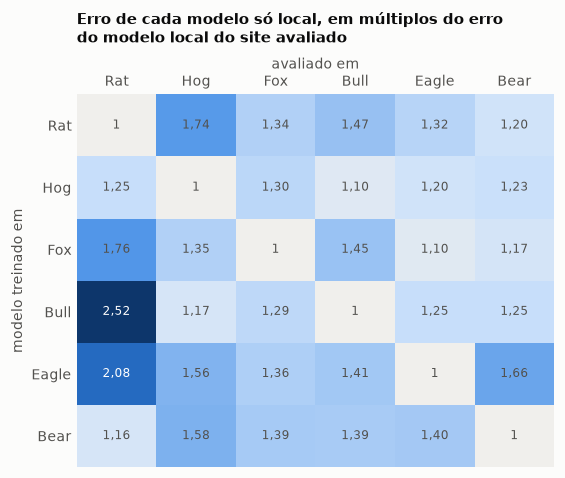

,CV(RMSE) % do próprio modelo,melhor modelo de outro site,CV(RMSE) % desse modelo,média dos modelos de outros sites
Rat,12.22,Bear,14.19,21.42
Hog,15.46,Bull,18.02,22.85
Fox,6.79,Bull,8.75,9.08
Bull,16.63,Hog,18.35,22.67
Eagle,7.26,Fox,7.98,9.10
Bear,8.23,Fox,9.66,10.70


In [6]:
cruz = pd.DataFrame(
    {alvo: {orig: 100 * rmse_cv(real[alvo], kwh(m_loc[orig], alvo))["cv_rmse"] for orig in sites}
     for alvo in sites})
cruz.index.name, cruz.columns.name = "modelo treinado em", "avaliado em"
razao = cruz / np.diag(cruz.values)

fig, ax = plt.subplots(figsize=(5.6, 4.4))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#f0efec"] + gr.SEQ_AZUL)
vmax = np.nanmax(razao.values)
ax.imshow(razao.values, cmap=cmap, vmin=1, vmax=vmax, aspect="auto")
for i in range(len(sites)):
    for j in range(len(sites)):
        v = razao.values[i, j]
        ax.text(j, i, "1" if i == j else f"{v:.2f}".replace(".", ","), ha="center", va="center",
                fontsize=8, color="#ffffff" if v > 1 + 0.55 * (vmax - 1) else gr.TINTA_2)
ax.set_xticks(range(len(sites)), sites)
ax.set_yticks(range(len(sites)), sites)
ax.xaxis.tick_top()
ax.set_xlabel("avaliado em")
ax.xaxis.set_label_position("top")
ax.set_ylabel("modelo treinado em")
ax.grid(False)
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.set_title("Erro de cada modelo só local, em múltiplos do erro\ndo modelo local do site avaliado",
             pad=34)
plt.show()

alheios = cruz.where(~np.eye(len(sites), dtype=bool))
pd.DataFrame({
    "CV(RMSE) % do próprio modelo": np.diag(cruz.values),
    "melhor modelo de outro site": alheios.idxmin(),
    "CV(RMSE) % desse modelo": alheios.min(),
    "média dos modelos de outros sites": alheios.mean(),
}, index=sites)

Nenhum modelo de outro site chega ao desempenho do modelo local: todas as células fora da diagonal
ficam acima de 1, entre 1,10 e 2,52. Rat é o site mais difícil de atender com um modelo alheio. O
modelo de Bull erra 2,5 vezes mais ali do que o modelo local de Rat, e o de Eagle, 2,1 vezes. Mesmo
o melhor modelo alheio para Rat, o de Bear, fica 16% pior.

Isso confirma o que a análise exploratória sugeria: os sites não compartilham uma mesma relação
entre as features e o consumo, e o modelo aprendido num site não se transfere bem para os outros.

## 4. Onde o modelo global perde

O site em que o FedAvg mais perde para o treino só local, olhando edificação por edificação:
quanto do erro quadrático do site cada edificação responde.

In [7]:
ganho = cv["FedAvg"] - cv["Só local"]
pior = ganho.drop("Total").idxmax()
va = clientes[pior]["val"].assign(prev_fed=prev[pior]["federado"], prev_loc=prev[pior]["local"])
por_edif = va.groupby("edif").apply(lambda d: pd.Series({
    "consumo médio (kWh/h)": d.y_kwh.mean(),
    "fatia do erro² FedAvg (%)": ((d.y_kwh - d.prev_fed) ** 2).sum(),
    "fatia do erro² só local (%)": ((d.y_kwh - d.prev_loc) ** 2).sum(),
}), include_groups=False)
for col in ["fatia do erro² FedAvg (%)", "fatia do erro² só local (%)"]:
    por_edif[col] = 100 * por_edif[col] / por_edif[col].sum()
print(f"Site com maior diferença entre FedAvg e só local: {pior} "
      f"({cv.loc[pior, 'FedAvg']:.1f}% contra {cv.loc[pior, 'Só local']:.1f}%)")
por_edif.sort_values("fatia do erro² FedAvg (%)", ascending=False).head(5)

Site com maior diferença entre FedAvg e só local: Rat (16.4% contra 12.2%)


,consumo médio (kWh/h),fatia do erro² FedAvg (%),fatia do erro² só local (%)
edif,,,
Rat_office_Colby,2209.22,55.59,38.62
Rat_office_Jamal,800.31,19.48,25.34
Rat_education_Beverly,604.01,7.12,9.23
Rat_education_Theo,474.62,4.81,6.93
Rat_office_Lora,402.64,4.70,6.83


A diferença entre os dois modelos não se espalha pelo ano. A tabela abaixo mostra as semanas em
que o RMSE do FedAvg nessa edificação mais se afasta do RMSE do modelo só local, e o gráfico mostra
a primeira delas.

,RMSE FedAvg,RMSE só local,diferença
semana,,,
13/11 a 19/11,609.0,227.0,382.0
28/08 a 03/09,692.0,337.0,355.0
12/06 a 18/06,486.0,299.0,187.0
11/12 a 17/12,340.0,216.0,124.0


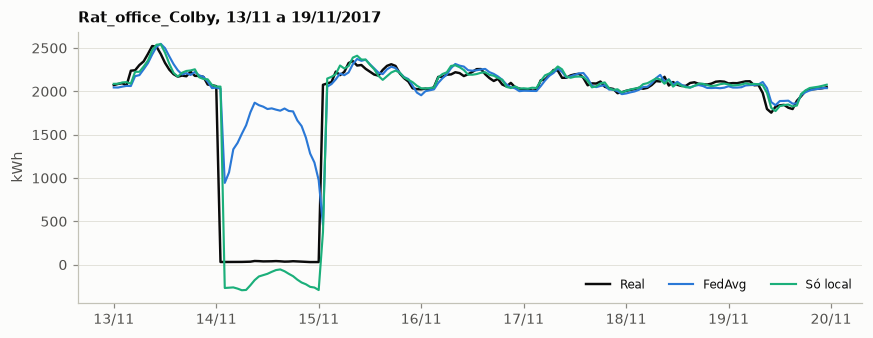

In [8]:
edif = por_edif["fatia do erro² FedAvg (%)"].idxmax()
e = va[va.edif == edif].set_index("ts")
sem = pd.DataFrame({
    "RMSE FedAvg": (e.y_kwh - e.prev_fed).pow(2).resample("W-SUN").mean().pow(0.5),
    "RMSE só local": (e.y_kwh - e.prev_loc).pow(2).resample("W-SUN").mean().pow(0.5),
})
sem["diferença"] = sem["RMSE FedAvg"] - sem["RMSE só local"]
fim = sem["diferença"].idxmax()
tabela = sem.sort_values("diferença", ascending=False).head(4).round(0)
tabela.index = [f"{(d - pd.Timedelta(days=6)):%d/%m} a {d:%d/%m}" for d in tabela.index]
tabela.index.name = "semana"
display(tabela)

semana = e.loc[fim - pd.Timedelta(days=6): fim + pd.Timedelta(hours=23)]

fig, ax = plt.subplots(figsize=(9.2, 3.2))
ax.plot(semana.index, semana.y_kwh, color=gr.TINTA, linewidth=1.6, label="Real")
ax.plot(semana.index, semana.prev_fed, color=gr.METODOS["federado"][1], linewidth=1.4, label="FedAvg")
ax.plot(semana.index, semana.prev_loc, color=gr.METODOS["local"][1], linewidth=1.4, label="Só local")
ax.set_ylabel("kWh")
ax.set_title(f"{edif}, {semana.index[0]:%d/%m} a {semana.index[-1]:%d/%m/%Y}")
ax.legend(loc="lower right", ncols=3)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m"))
plt.show()

Em Rat, uma única edificação, a `Rat_office_Colby`, com ~2.200 kWh/h de consumo médio em 2017,
responde por 56% do erro quadrático do FedAvg no site, contra 39% no modelo local. E a diferença
entre os dois modelos nessa edificação vem de poucos eventos.

Na semana do gráfico, o prédio ficou praticamente desligado durante o dia 14/11, com cerca de 40
kWh/h. O modelo local acompanhou a queda já na hora seguinte, porque aprendeu a confiar muito no lag
t-1. Ele também erra, ficando abaixo de zero, mas por ~300 kWh. O modelo global continuou prevendo
perto de 1.800 kWh/h o dia inteiro, apoiado no que acontecia 24 h e 168 h antes. Fora desses
eventos, as duas previsões quase se sobrepõem.

Uma leitura possível: o peso que cada site dá ao lag t-1, em relação aos lags t-24 e t-168, depende
da frequência desse tipo de evento nos dados dele. O modelo global fica com um peso intermediário e
erra justamente nessas horas, no prédio que mais pesa no RMSE em kWh. Os dados sugerem essa
hipótese, mas ela não foi testada separadamente.

## Conclusão

- **O FedAvg converge rápido, mas acrescenta pouco.** Em 3 rodadas o modelo global chega ao
  patamar final. O erro total (13,3% de CV(RMSE)) fica só 1,1 ponto abaixo do random walk (14,4%),
  e em Rat, Hog e Bull a vantagem é menor que 1 ponto.
- **E perde para o treino só local em todos os seis sites** (11,2% no total). Na maioria a
  perda é pequena. Em Rat, onde a reação a eventos raros num prédio muito grande pesa no erro, ela
  chega a 4,1 pontos.
- **O treino centralizado também não resolve** (15,7% no total, pior que o FedAvg e que o random
  walk). O problema não é a federação nem a falta de dados. É usar um único modelo para clientes
  com relações diferentes entre features e consumo, como mostram a análise exploratória e a matriz
  cruzada.

Neste cenário, cada site tem um ano inteiro de dados horários de 20 edificações, ou seja, dado
próprio de sobra. Aqui o argumento a favor do FL não é acurácia, é não precisar centralizar o dado
bruto. Para o FL também ganhar em acurácia com clientes tão diferentes, o modelo precisa ser
personalizado por cliente sem perder a parte compartilhada. Caminhos a testar:

- **Fine-tuning local depois do FedAvg:** cada site treina mais algumas épocas a partir do modelo
  global.
- **FedPer** (Arivazhagan et al., 2019): as camadas iniciais são federadas e a última fica local em
  cada site.
- **LoRA personalizado**, como o FedSA-LoRA (Guo et al., 2025): o modelo global fica congelado e
  cada site treina adaptadores de baixo posto, dos quais só uma parte vai para a média.
- **FL clusterizado** (Ghosh et al., 2020): sites parecidos treinam um modelo comum entre si.

Também vale repetir a comparação com pouco dado por site, por exemplo 1 ou 2 meses de treino. É
nesse regime que o treino local costuma falhar e a federação costuma compensar.

**Limitações:**

- uma única seed e um único split;
- nenhuma busca de hiperparâmetros;
- os picos de leitura acumulada em Bull entram no treino sem tratamento (ver `eda.ipynb`);
- a seleção descarta edificações que mudam de patamar entre 2016 e 2017, o que deixa o problema
  mais fácil do que na operação real.